In [1]:
# package import
import numpy as np
from numpy import arange
import pandas as pd
from pandas import read_csv
from pandas import set_option
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error



In [2]:
# loading data
X_train_data = pd.read_csv("X_train_processed_61.csv")
y_train_data = pd.read_csv("y_train.csv")

X_train = X_train_data.values
y_train = y_train_data.values.ravel()

In [3]:
# starting model:
# healthcare_system_confidence, -government_covid_response, -i11_health
# -perceived_covid_severity, -age, -avoiding_infected_people
# -hand_sanitizer_frequency
# -i12_health_13, -i12_health_22, -i12_health_25

starting_cols = [
    "cat__healthcare_system_confidence_A fair amount of confidence",
    "cat__healthcare_system_confidence_A lot of confidence",
    "cat__healthcare_system_confidence_Don't know",
    "cat__healthcare_system_confidence_No confidence at all",
    "cat__healthcare_system_confidence_Not very much confidence",
    "cat__government_covid_response_Don't know",
    "cat__government_covid_response_Somewhat badly",
    "cat__government_covid_response_Somewhat well",
    "cat__government_covid_response_Very badly",
    "cat__government_covid_response_Very well",
    "ord__i11_health",
    "ord__perceived_covid_severity",
    "num__age",
    "ord__avoiding_infected_people",
    "ord__hand_sanitizer_frequency",
    "ord__i12_health_13",
    "ord__i12_health_22",
    "ord__i12_health_25",
]

In [4]:
# expanded model
# starting model + perceived_infection_risk + employment_status

expanded_cols = starting_cols + [
    "ord__perceived_infection_risk",
    "cat__employment_status_Full time employment",
    "cat__employment_status_Full time student",
    "cat__employment_status_Not working",
    "cat__employment_status_Other",
    "cat__employment_status_Part time employment",
    "cat__employment_status_Retired",
    "cat__employment_status_Unemployed",
]

In [5]:
# compact model
# starting model - last four variables

compact_cols = [
    "cat__healthcare_system_confidence_A fair amount of confidence",
    "cat__healthcare_system_confidence_A lot of confidence",
    "cat__healthcare_system_confidence_Don't know",
    "cat__healthcare_system_confidence_No confidence at all",
    "cat__healthcare_system_confidence_Not very much confidence",
    "cat__government_covid_response_Don't know",
    "cat__government_covid_response_Somewhat badly",
    "cat__government_covid_response_Somewhat well",
    "cat__government_covid_response_Very badly",
    "cat__government_covid_response_Very well",
    "ord__i11_health",
    "ord__perceived_covid_severity",
    "num__age",
    "ord__avoiding_infected_people",
]

In [6]:
compact_plus_cols = compact_cols + [
    "ord__perceived_infection_risk",
    "cat__employment_status_Full time employment",
    "cat__employment_status_Full time student",
    "cat__employment_status_Not working",
    "cat__employment_status_Other",
    "cat__employment_status_Part time employment",
    "cat__employment_status_Retired",
    "cat__employment_status_Unemployed",
]


In [8]:
X_train_starting = X_train_data[starting_cols].values
X_train_expanded = X_train_data[expanded_cols].values
X_train_compact = X_train_data[compact_cols].values
X_train_compact_plus = X_train_data[compact_plus_cols].values

In [ ]:
feature_sets = {
    "all_61": X_train,
    "starting_model": X_train_starting,
    "expanded_model": X_train_expanded,
    "compact_model": X_train_compact,
}

In [ ]:
num_folds = 10
seed = 42


kfold = StratifiedKFold(n_splits=num_folds, random_state=seed, shuffle=True)

model = KNeighborsClassifier()
weighted_model_euclidean = KNeighborsClassifier(weights='distance')
weighted_model_manhattan = KNeighborsClassifier(weights='distance', metric="manhattan")
weighted_model_chebyshev = KNeighborsClassifier(weights='distance', metric="chebyshev")


In [11]:
# different k values list to try
# k_values = [3, 5, 7, 9, 11, 21, 31, 41, 51, 61, 71]
k_values = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25]
param_grid = dict(n_neighbors=k_values)
mse_scoring = 'neg_mean_squared_error'
balacc_scoring = 'balanced_accuracy'

In [12]:
# k-fold cross validation for each feature set with different models

settings = {
    "uniform":   model,
    "euclidean": weighted_model_euclidean,
    "manhattan": weighted_model_manhattan,
    "chebyshev": weighted_model_chebyshev,
}

rows = []
for name, X_sub in feature_sets.items():
    # scale this model's columns
    rescaledX = StandardScaler().fit_transform(X_sub)

    for setting, estimator in settings.items():
        # try every k with 10-fold CV
        grid = GridSearchCV(estimator=estimator, param_grid=param_grid,
                            scoring=mse_scoring, cv=kfold)
        grid.fit(rescaledX, y_train)

        for k, mean, std in zip(k_values,
                                grid.cv_results_['mean_test_score'],
                                grid.cv_results_['std_test_score']):
            rows.append({"model": name, "setting": setting, "k": k,
                         "cv_mse": -mean, "cv_std": std})

mse_df = pd.DataFrame(rows)
mse_df.head()

,model,setting,k,cv_mse,cv_std
0,all_61,uniform,3,0.232885,0.015438
1,all_61,uniform,5,0.232886,0.012557
2,all_61,uniform,7,0.231532,0.008484
3,all_61,uniform,9,0.230950,0.009664
4,all_61,uniform,11,0.233283,0.010199


In [14]:
mse_df.to_csv("mse_results.csv", index=False)
mse_df = pd.read_csv("mse_results.csv")

In [28]:
balacc_rows = []
for name, X_sub in feature_sets.items():
    # scale this model's columns
    rescaledX = StandardScaler().fit_transform(X_sub)

    for setting, estimator in settings.items():
        # try every k with 10-fold CV
        grid = GridSearchCV(estimator=estimator, param_grid=param_grid,
                            scoring=balacc_scoring, cv=kfold)
        grid.fit(rescaledX, y_train)

        for k, mean, std in zip(k_values,
                                grid.cv_results_['mean_test_score'],
                                grid.cv_results_['std_test_score']):
            balacc_rows.append({"model": name, "setting": setting, "k": k,
                                "cv_bal_acc": mean, "cv_std": std})

balacc_df = pd.DataFrame(balacc_rows)
balacc_df.head()

,model,setting,k,cv_bal_acc,cv_std
0,all_61,uniform,3,0.675828,0.017671
1,all_61,uniform,5,0.661402,0.018860
2,all_61,uniform,7,0.648551,0.015114
3,all_61,uniform,9,0.640506,0.019115
4,all_61,uniform,11,0.629601,0.017783


In [29]:
balacc_df.to_csv("balacc_results.csv", index=False)
balacc_df = pd.read_csv("balacc_results.csv")

In [25]:
colors = {"all_61": "C0", "starting_model": "C1",
          "expanded_model": "C2", "compact_model": "C3"}

line_styles = {"uniform": "-", "manhattan": "-.", 'euclidean': "--"}

model_names = {"all_61": "All 61 features",
               "starting_model": "Starting model",
               "expanded_model": "Expanded model",
               "compact_model": "Compact model"}

setting_names = {"uniform": "Uniform",
                 "manhattan": "Manhattan",
                 "euclidean": "Euclidean"}


In [26]:
pairs = [
    # uniform
    ("all_61", "uniform"),
    ("starting_model", "uniform"),
    ("expanded_model", "uniform"),
    ("compact_model", "uniform"),

    # manhattan
    ("all_61", "manhattan"),
    ("starting_model", "manhattan"),
    ("expanded_model", "manhattan"),
    ("compact_model", "manhattan"),

    # euclidean
    ("compact_model", "euclidean"),
]

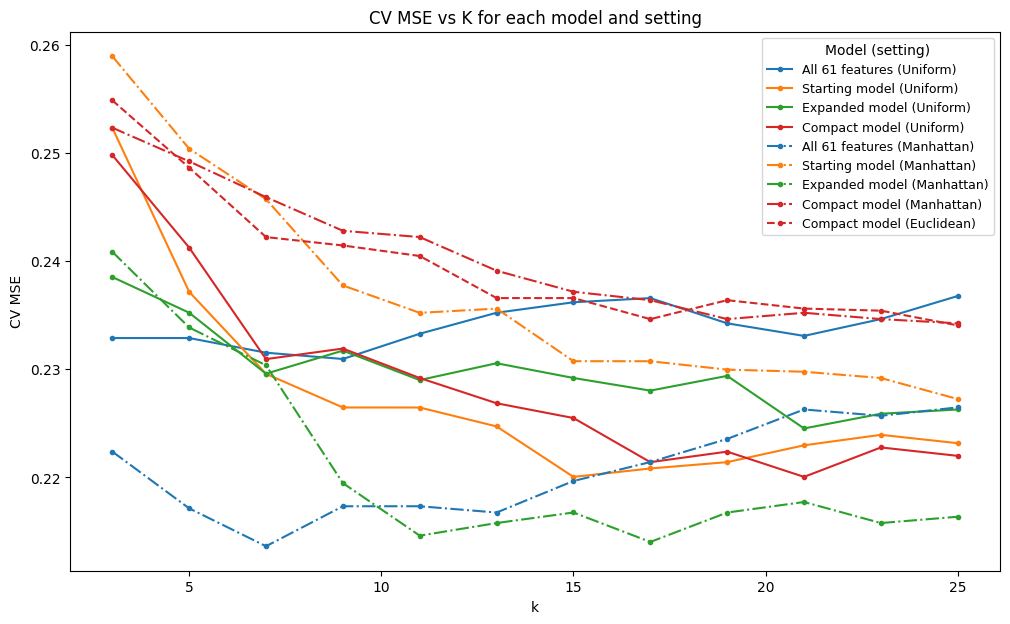

In [ ]:
plt.figure(figsize=(12, 7))   

for model, setting in pairs:
    subset = mse_df[(mse_df["model"] == model) & (mse_df["setting"] == setting)]
    plt.plot(subset["k"], subset["cv_mse"],
             marker="o",
             markersize=3,
             color=colors[model],
             linestyle=line_styles[setting],
             label=model_names[model] + " (" + setting_names[setting] + ")")

plt.xlabel("k")
plt.ylabel("CV MSE")
plt.title("CV MSE vs K for each model and setting")
plt.legend(title="Model (setting)", fontsize=9, loc="upper right")
plt.show()

In [32]:
balacc_colors = {"starting_model": "C1", "expanded_model": "C2",
                 "compact_model": "C3", "compact_plus_model": "C4", "compact_ultra_model": "C5"}

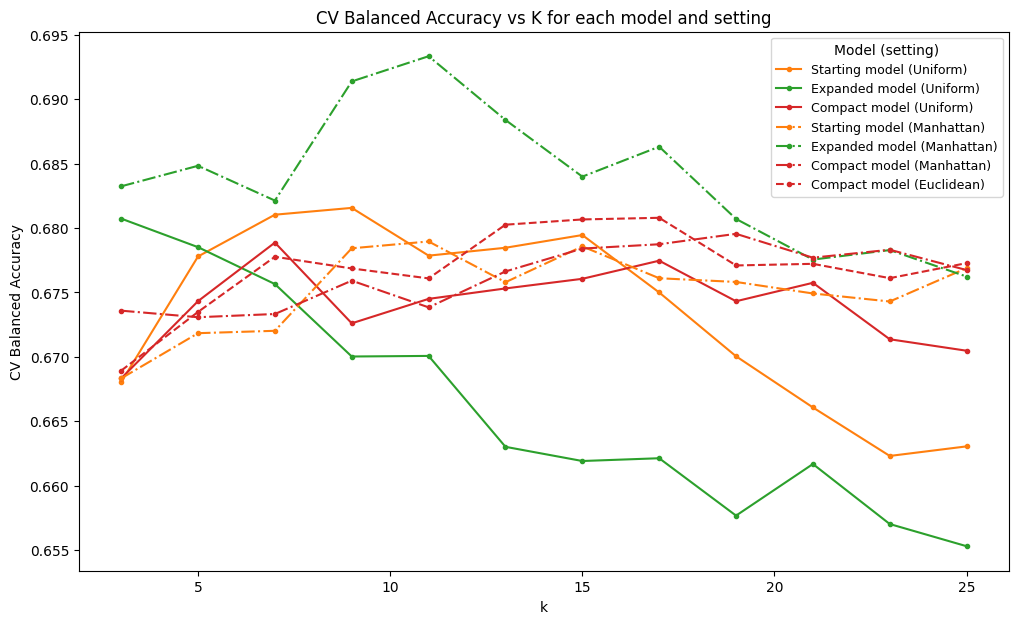

In [34]:
plt.figure(figsize=(12, 7))  

for model, setting in pairs:
    if model not in balacc_colors:      # skips all_61
        continue
    subset = balacc_df[(balacc_df["model"] == model) & (balacc_df["setting"] == setting)]
    plt.plot(subset["k"], subset["cv_bal_acc"],
             marker="o",
             markersize=3,
             color=balacc_colors[model],
             linestyle=line_styles[setting],
             label=model_names[model] + " (" + setting_names[setting] + ")")

plt.xlabel("k")
plt.ylabel("CV Balanced Accuracy")
plt.title("CV Balanced Accuracy vs K for each model and setting")
plt.legend(title="Model (setting)", fontsize=9, loc="upper right")
plt.show()